# State of Charge (SOC) Estimation for the BMW i3 using a Temporal Convolutional Network (TCN)

**Name:** RHYTHM GARG &nbsp; | &nbsp; **Reg. No.:** 25BBS0153

**Base paper:** M. H. Sulaiman and Z. Mustaffa, "State of charge estimation for electric vehicles
using random forest", *Green Energy and Intelligent Transportation*, 3 (2024) 100177.

**Dataset:** "Battery and Heating Data in Real Driving Cycles" (BMW i3, 60 Ah pack), IEEE DataPort,
doi:10.21227/6jr9-5235 — 70 real driving trips, supplied as two files: trips 1–60 (training)
and trips 61–70 (testing).

**Preprocessing (as in the base paper)**
1. Inputs: battery voltage (V), battery current (A), battery temperature (°C), ambient temperature (°C).
   Output: SOC (%) estimated by the manufacturer (the `SoC [%]` column, *not* `displayed SoC`).
2. All trips combined into one dataset with aligned readings, sampled at 1 Hz.
3. Missing values (NaN) and inconsistent / noisy records removed.
4. Trips #1–#60 for training, trips #61–#70 for testing.
5. Evaluation metrics: RMSE, MAE, MAX error, STD. DEV. of error, computation time.

**Proposed method – physics-informed TCN:** all inputs are derived causally from the four measured signals.
1. *Coulomb counting* – ΔSOC since the start of the trip from the integrated current (∫ I dt).
2. *Voltage model* – a polynomial ridge regression of SOC on voltage, battery temperature and current
   history (OCV curve + temperature shift + IR / polarisation drop).
3. *Fusion* – the slowly varying offset between (2) and (1) is averaged causally within each trip and
   blended by a second ridge model (all training features computed out-of-fold, trip-wise CV).
4. *TCN* – a causal TCN (dilated 1-D convolutions, residual blocks) sees the last `SEQ_LEN` samples of the
   signals and the physics estimates and adds a bounded correction (±`RES_SCALE`) to the fused estimate.

A 25-tree Random Forest (the paper's best configuration) is trained on the same data as the reference model.

In [1]:
import platform, psutil, cpuinfo
print("=" * 50)
print(f"Python       : {platform.python_version()}")
try:
    import torch as _t
    print(f"PyTorch      : {_t.__version__}")
    if _t.cuda.is_available():
        print(f"GPU          : {_t.cuda.get_device_name(0)}")
    else:
        print("GPU          : None (CPU mode)")
except Exception:
    pass
try:
    info = cpuinfo.get_cpu_info()
    print(f"CPU          : {info.get('brand_raw', 'unknown')}")
except Exception:
    print(f"CPU          : {platform.processor()}")
print(f"RAM          : {psutil.virtual_memory().total / (1024**3):.1f} GB")
print(f"OS           : {platform.system()} {platform.release()}")
print("=" * 50)
del _t

Python       : 3.10.0


PyTorch      : 2.14.1+cpu
GPU          : None (CPU mode)


CPU          : 12th Gen Intel(R) Core(TM) i5-1235U
RAM          : 7.7 GB
OS           : Windows 10


In [2]:
import glob
import os
import random
import time

import matplotlib
import sys
if "ipykernel" not in sys.modules:   # plain script: save figures only; notebook: show them inline
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.ensemble import RandomForestRegressor

# ---------------- USER SETTINGS ----------------
DATA_DIR = r"./BMW_i3_dataset"   # folder containing the two dataset files below
TRAIN_FILE = None                # None = auto-detect the file with "train" in its name, or give the file name
TEST_FILE = None                 # None = auto-detect the file with "test" in its name, or give the file name
OUT_DIR = r"./outputs"           # figures, tables, predictions and model weights are saved here
SEQ_LEN = 120                    # samples of history the TCN sees (raw data is 10 Hz)
TRAIN_STRIDE = 40                # use every 40th training window per epoch
BATCH_SIZE = 512
MAX_EPOCHS = 8
PATIENCE = 3                     # early-stopping patience (epochs)
LR = 1e-3
CHANNELS = 32
KERNEL = 3
DILATIONS = [1, 2, 4, 8, 16]
DROPOUT = 0.2
RES_SCALE = 0.03                 # TCN may correct the physics estimate by at most +/-3 % SOC
WEIGHT_DECAY = 0.01              # AdamW weight decay (limits over-fitting to training trips)
CV_FOLDS = 6                     # trip-wise folds for out-of-fold physics features on training trips
VAL_TRIPS = 6                    # last 6 of the 60 training trips held out for early stopping
SMOOTH_WIN = 60                  # causal moving-average window (samples) on the output; 1 = off
RUN_RF_BASELINE = True           # train the paper's 25-tree RF for comparison
SEED = 42
# ------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.14.1+cpu | device: cpu


## 1. Data loading and preprocessing

In [3]:
FEATURES = ["Voltage", "Current", "BatteryTemp", "AmbientTemp"]
os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)


def show(name):
    """Save the current figure to outputs/figures and display it."""
    plt.savefig(os.path.join(OUT_DIR, "figures", name + ".png"), dpi=300, bbox_inches="tight")
    plt.show()


def find_file(user_choice, key):
    if user_choice:
        return os.path.join(DATA_DIR, user_choice)
    cands = [f for f in glob.glob(os.path.join(DATA_DIR, "*"))
             if key in os.path.basename(f).lower() and f.lower().endswith((".csv", ".xlsx", ".xls", ".txt"))]
    assert len(cands) == 1, f"Could not find exactly one '{key}' file in {DATA_DIR}: {cands}"
    return cands[0]


def read_table(path):
    if path.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    with open(path, "r", encoding="latin-1") as fh:
        head = fh.readline()
    counts = {";": head.count(";"), ",": head.count(","), "\t": head.count("\t")}
    sep = max(counts, key=counts.get)
    return pd.read_csv(path, sep=sep, encoding="latin-1", low_memory=False)


def pick(cols, test, name, path, required=True):
    for c in cols:
        if test(c.lower()):
            return c
    if required:
        raise KeyError(f"No '{name}' column in {os.path.basename(path)}. Columns: {list(cols)}")
    return None


def load_split(path, first_trip_id):
    """Read one combined file, keep the paper's 4 inputs + manufacturer SOC,
    clean it, recover trip boundaries and put every trip on a 1 Hz grid."""
    df = read_table(path)
    df.columns = [str(c).strip() for c in df.columns]
    cols = df.columns
    print(f"\n{os.path.basename(path)}: {len(df):,} rows\nColumns: {list(cols)}")
    col = {
        "Voltage": pick(cols, lambda c: "volt" in c, "battery voltage", path),
        "Current": pick(cols, lambda c: "current" in c, "battery current", path),
        "BatteryTemp": pick(cols, lambda c: "temp" in c and ("batt" in c or "cell" in c) and "max" not in c,
                            "battery temperature", path),
        "AmbientTemp": pick(cols, lambda c: "amb" in c, "ambient temperature", path),
        "SOC": pick(cols, lambda c: ("soc" in c or "state of charge" in c) and "display" not in c
                    and not c.startswith(("min", "max")), "SoC (manufacturer)", path),
    }
    time_col = pick(cols, lambda c: c.startswith("time") or c in ("t", "t [s]", "sec", "seconds"),
                    "time", path, required=False)
    trip_col = pick(cols, lambda c: "trip" in c, "trip", path, required=False)
    print("Column mapping:", col, "| time:", time_col, "| trip:", trip_col)

    out = pd.DataFrame({k: pd.to_numeric(df[v].astype(str).str.replace(",", "."), errors="coerce")
                        for k, v in col.items()})
    out["Time"] = pd.to_numeric(df[time_col], errors="coerce") if time_col else np.arange(len(df), dtype=float)
    # --- trip boundaries: trip-ID column > time resets > one continuous sequence ---
    if trip_col:
        out["trip_raw"] = pd.factorize(df[trip_col])[0]
        how = f"column '{trip_col}'"
    elif time_col:
        out["trip_raw"] = (out.Time.diff() < 0).cumsum()
        how = "time resets"
    else:
        out["trip_raw"] = 0
        how = "none found (treated as one continuous sequence)"
    n_raw = len(out)
    # --- cleaning: missing values and physically inconsistent records ---
    out = out.dropna()
    out = out[(out.Voltage > 0) & (out.SOC >= 0) & (out.SOC <= 100)
              & out.BatteryTemp.between(-40, 80) & out.AmbientTemp.between(-40, 60)]
    # noisy records: SOC jumping by more than 5 % between consecutive samples (logging glitch)
    out = out[~(out.groupby("trip_raw").SOC.diff().abs() > 5)]
    # --- keep all raw rows (paper uses each row as one instance); assign trip IDs ---
    parts = []
    for k, (_, g) in enumerate(out.groupby("trip_raw", sort=False)):
        g = g[FEATURES + ["SOC", "Time"]].reset_index(drop=True)
        g["sec"] = np.arange(len(g))
        g["trip"] = first_trip_id + k
        parts.append(g)
    res = pd.concat(parts, ignore_index=True)
    print(f"Trip boundaries from {how}: {len(parts)} trip(s) | rows raw {n_raw:,} -> cleaned {len(res):,}")
    return res


train_path, test_path = find_file(TRAIN_FILE, "train"), find_file(TEST_FILE, "test")
train_df = load_split(train_path, first_trip_id=1)
test_df = load_split(test_path, first_trip_id=int(train_df.trip.max()) + 1)
data = pd.concat([train_df, test_df], ignore_index=True)

all_train_ids = sorted(train_df.trip.unique().tolist())
test_ids = sorted(test_df.trip.unique().tolist())

# If trip boundaries could not be recovered, hold out the last 10 % of the training sequence for validation.
if len(all_train_ids) <= VAL_TRIPS:
    last = all_train_ids[-1]
    m = data.trip == last
    cut = data.index[m][int(m.sum() * 0.9)]
    new_id = int(data.trip.max()) + 1
    data.loc[m & (data.index >= cut), "trip"] = new_id
    all_train_ids = all_train_ids + [new_id]
    VAL_TRIPS = 1
    train_df = data[data.trip.isin(all_train_ids)]
    print("Few trips found: last 10 % of the training sequence used as validation.")

summary = data.groupby("trip").agg(Rows=("SOC", "size"), SOC_start=("SOC", "first"), SOC_end=("SOC", "last"))
summary["Set"] = np.where(summary.index.isin(test_ids), "test", "train")
print(summary.round(2).to_string())
print(f"\nTotal instances: {len(data):,} | training: {len(train_df):,} ({len(all_train_ids)} trips) "
      f"| testing: {len(test_df):,} ({len(test_ids)} trips)")
print(data[FEATURES + ["SOC"]].describe().round(2))


Final_60trips_Training_BMW_Data.csv: 945,026 rows
Columns: ['Time [s]', 'Battery Voltage [V]', 'Battery Current [A]', 'Battery Temperature [°C]', 'Ambient Temperature [°C]', 'SoC [%]']
Column mapping: {'Voltage': 'Battery Voltage [V]', 'Current': 'Battery Current [A]', 'BatteryTemp': 'Battery Temperature [°C]', 'AmbientTemp': 'Ambient Temperature [°C]', 'SOC': 'SoC [%]'} | time: Time [s] | trip: None


Trip boundaries from time resets: 60 trip(s) | rows raw 945,026 -> cleaned 945,025

Final_10trips_Testing_BMW_Data.csv: 118,974 rows
Columns: ['Time [s]', 'Battery Voltage [V]', 'Battery Current [A]', 'Battery Temperature [°C]', 'Ambient Temperature [°C]', 'SoC [%]']
Column mapping: {'Voltage': 'Battery Voltage [V]', 'Current': 'Battery Current [A]', 'BatteryTemp': 'Battery Temperature [°C]', 'AmbientTemp': 'Ambient Temperature [°C]', 'SOC': 'SoC [%]'} | time: Time [s] | trip: None


Trip boundaries from time resets: 10 trip(s) | rows raw 118,974 -> cleaned 118,974
       Rows  SOC_start  SOC_end    Set
trip                                  
1     10090       86.9     81.5  train
2     14130       80.3     67.3  train
3      6706       83.5     75.1  train
4      4124       75.1     66.7  train
5     13667       66.7     60.2  train
6     31645       85.1     63.4  train
7     20933       63.4     34.2  train
8     28059       86.6     76.1  train
9     18344       74.7     68.6  train
10    14176       69.6     60.9  train
11    14245       87.0     75.6  train
12    16384       75.5     64.3  train
13     7160       85.8     82.9  train
14     6946       82.8     79.9  train
15    22348       74.8     63.4  train
16    19066       63.0     46.8  train
17     6687       86.8     77.9  train
18     8808       77.9     70.2  train
19    15876       88.5     80.4  train
20    17196       77.0     69.1  train
21    19829       71.3     63.7  train
22    18388       87

          Voltage     Current  BatteryTemp  AmbientTemp         SOC
count  1063999.00  1063999.00   1063999.00   1063999.00  1063999.00
mean       376.21      -19.44        15.50        13.22       65.10
std         11.80       42.26         7.51         9.71       15.11
min        301.80     -404.38        -1.00        -3.50       15.40
25%        369.02      -32.06         9.00         5.00       56.47
50%        379.29      -11.89        15.00         9.50       68.20
75%        385.10       -2.10        21.00        22.00       76.50
max        394.76      144.49        32.00        33.50       88.50


## 1b. Physics-informed features (causal, built only from the 4 measured signals)
* **Coulomb counting:** ΔSOC(t) = k · ∫ I dt since the start of the trip. k (1 / effective capacity) is
  fitted on the training trips only.
* **Stage 1 – voltage model:** a polynomial ridge regression SOC ≈ f(V, T_batt, current history) that
  captures the OCV curve, its temperature shift and the IR / polarisation drop. Its estimates are noisy and
  biased per trip, but the bias changes slowly.
* **Stage 2 – fusion:** within each trip, the offset f − ΔSOC is averaged causally (exponential averages
  with several half-lives, optionally weighting low-current samples) and added back to ΔSOC. A second ridge
  blends these estimates. On training trips every feature is computed **out-of-fold** (trip-wise CV), so the
  TCN later sees errors as large as it will see on unseen trips.

In [4]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold

FS = int(round(1 / data.groupby("trip").Time.diff().median()))      # samples per second
trip_of = data.trip.values
dt = data.groupby("trip").Time.diff().fillna(0).clip(0, 5)
data["Ah"] = (data.Current * dt).groupby(trip_of).cumsum() / 3600
is_tr = data.trip.isin(all_train_ids).values
d_soc = (data.SOC - data.groupby("trip").SOC.transform("first")).values
K_CC = np.sum(d_soc[is_tr] * data.Ah.values[is_tr]) / np.sum(data.Ah.values[is_tr] ** 2)
data["dsoc"] = K_CC * data.Ah
print(f"Sampling rate: {FS} Hz | coulomb-counting gain k = {K_CC:.4f} %/Ah (effective capacity {100 / K_CC:.2f} Ah)")
for w in (10, 60, 300):
    data[f"I_m{w}"] = data.groupby("trip").Current.transform(lambda s: s.rolling(w * FS, min_periods=1).mean())
    data[f"Ia_m{w}"] = data.Current.abs().groupby(trip_of).transform(lambda s: s.rolling(w * FS, min_periods=1).mean())
data["tsec"] = data.groupby("trip").cumcount() / FS


def poly(d):
    v = (d.Voltage.values - 375) / 15
    tb = (d.BatteryTemp.values - 15) / 10
    cols = [v, v ** 2, v ** 3, tb, tb * v, tb ** 2, tb * v ** 2]
    for c in ["Current", "I_m10", "I_m60", "I_m300", "Ia_m60", "Ia_m300"]:
        x = d[c].values / 50
        cols += [x, x * tb, x * v]
    return np.column_stack(cols)


def fused(d, g):
    """Stage-2 inputs: causal per-trip averages of (g - ΔSOC) added back to ΔSOC."""
    trips = d.trip.values
    off = pd.Series(g - d.dsoc.values)
    w = pd.Series(1.0 / (1.0 + (d.Ia_m60.values / 5) ** 2))       # trust low-current samples more
    cols = [g]
    for hl in (30, 120, 600, 3000):
        h = hl * FS
        cols.append(off.groupby(trips).transform(lambda s: s.ewm(halflife=h).mean()).values + d.dsoc.values)
        num = (off * w).groupby(trips).transform(lambda s: s.ewm(halflife=h).mean())
        den = w.groupby(trips).transform(lambda s: s.ewm(halflife=h).mean())
        cols.append((num / den).values + d.dsoc.values)
    cols.append(pd.Series(g).groupby(trips).transform(lambda s: s.expanding().mean()).values)
    return np.column_stack(cols + [np.log1p(d.tsec.values), d.dsoc.values])


def rmse_pct(p, y):
    return float(np.sqrt(np.mean((p - y) ** 2)))


t_phys0 = time.perf_counter()
dtr, dte = data[is_tr], data[~is_tr]
folds = list(GroupKFold(n_splits=CV_FOLDS).split(dtr, groups=dtr.trip.values))
P_tr = poly(dtr)
g_tr = np.zeros(len(dtr))
for a, b in folds:                                   # stage 1, out-of-fold on training trips
    g_tr[b] = Ridge(1e-3).fit(P_tr[a], dtr.SOC.values[a]).predict(P_tr[b])
g_te = Ridge(1e-3).fit(P_tr, dtr.SOC.values).predict(poly(dte))
F_tr, F_te = fused(dtr, g_tr), fused(dte, g_te)
p2_tr = np.zeros(len(dtr))
for a, b in folds:                                   # stage 2, out-of-fold on training trips
    p2_tr[b] = Ridge(1.0).fit(F_tr[a], dtr.SOC.values[a]).predict(F_tr[b])
p2_te = Ridge(1.0).fit(F_tr, dtr.SOC.values).predict(F_te)
phys_time = time.perf_counter() - t_phys0
data.loc[is_tr, "g"], data.loc[~is_tr, "g"] = g_tr, g_te
data.loc[is_tr, "p2"], data.loc[~is_tr, "p2"] = p2_tr, p2_te
print(f"Physics features built in {phys_time:.1f} s")
print(f"  stage 1 (voltage model)  : train-CV RMSE {rmse_pct(g_tr, dtr.SOC.values):.3f}% | "
      f"test RMSE {rmse_pct(g_te, dte.SOC.values):.3f}%")
print(f"  stage 2 (fusion with CC) : train-CV RMSE {rmse_pct(p2_tr, dtr.SOC.values):.3f}% | "
      f"test RMSE {rmse_pct(p2_te, dte.SOC.values):.3f}%")

Sampling rate: 10 Hz | coulomb-counting gain k = 1.6150 %/Ah (effective capacity 61.92 Ah)


Physics features built in 15.2 s
  stage 1 (voltage model)  : train-CV RMSE 3.381% | test RMSE 3.907%
  stage 2 (fusion with CC) : train-CV RMSE 2.591% | test RMSE 3.487%


In [5]:
x_min = train_df[FEATURES].min().values
x_max = train_df[FEATURES].max().values
x_max = np.where(x_max - x_min == 0, x_min + 1.0, x_max)   # guard against a constant column
TCN_IN = FEATURES + ["p2", "g", "dsoc"]          # SOC-like channels are passed as fractions (÷100)
BASE_CH = TCN_IN.index("p2")


def scale(df):
    raw = (df[FEATURES].values - x_min) / (x_max - x_min)
    return np.hstack([raw, df[["p2", "g", "dsoc"]].values / 100.0]).astype(np.float32)


trip_X = {t: scale(g) for t, g in data.groupby("trip")}
trip_y = {t: (g.SOC.values / 100.0).astype(np.float32) for t, g in data.groupby("trip")}

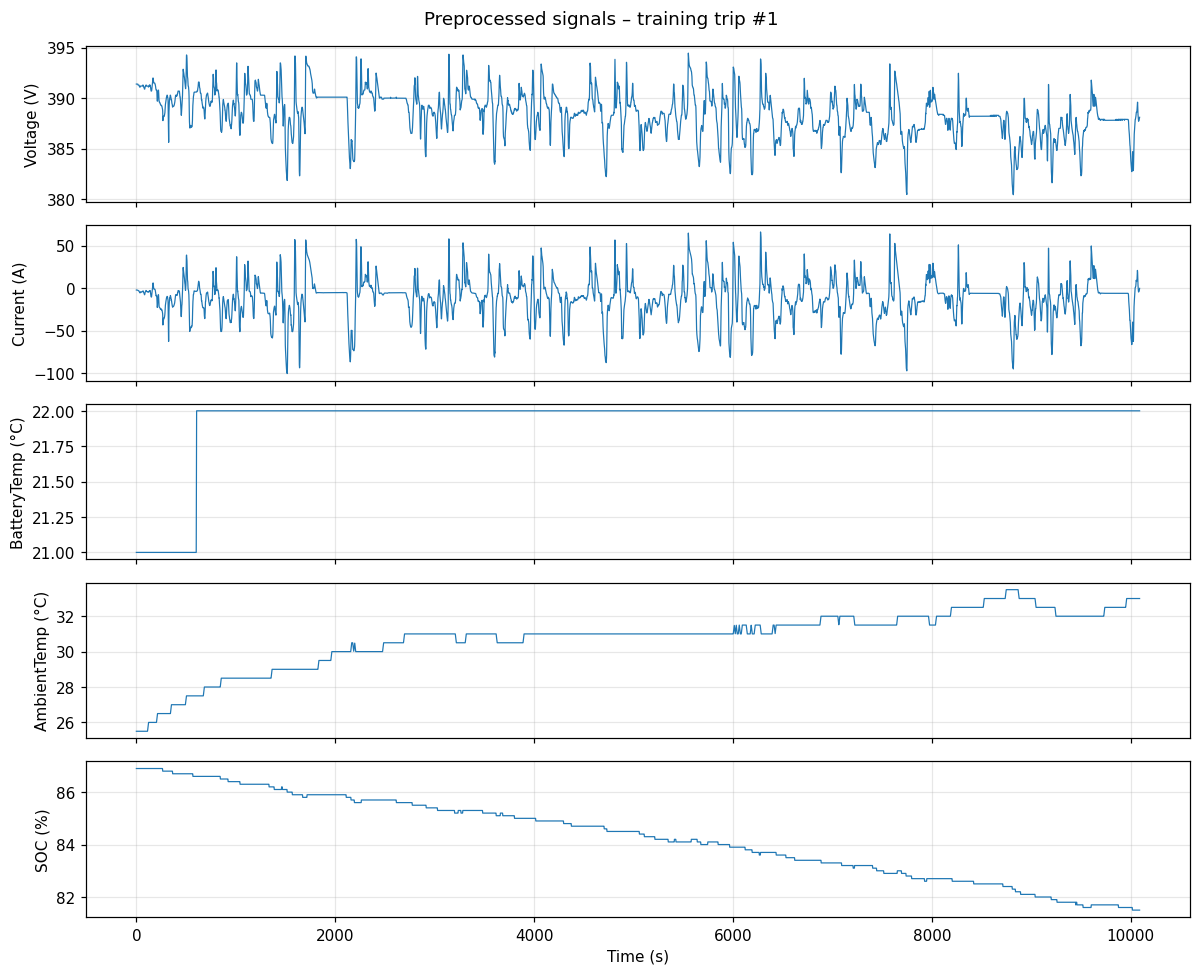

In [6]:
t0 = all_train_ids[0]
g = data[data.trip == t0]
fig, ax = plt.subplots(5, 1, figsize=(11, 9), sharex=True)
for a, c, u in zip(ax, FEATURES + ["SOC"], ["V", "A", "°C", "°C", "%"]):
    a.plot(g.sec, g[c], lw=0.8)
    a.set_ylabel(f"{c} ({u})")
ax[-1].set_xlabel("Time (s)")
fig.suptitle(f"Preprocessed signals – training trip #{t0}")
plt.tight_layout()
show("01_training_trip_signals")

## 2. Sliding-window sequences
Each sample is the last `SEQ_LEN` seconds of the 4 inputs; the target is the SOC at the final second.
The start of every trip is padded with its first reading, so every test instance gets an estimate
(as in the paper, errors are largest at the very start of a trip when little history is available).

In [7]:
def build_padded(trip_ids):
    Xs, ys, ends = [], [], []
    offset = 0
    for t in trip_ids:
        X, y = trip_X[t], trip_y[t]
        pad = np.repeat(X[:1], SEQ_LEN - 1, axis=0)
        Xp = np.vstack([pad, X])
        Xs.append(Xp)
        ys.append(y)
        ends.append(offset + SEQ_LEN - 1 + np.arange(len(X)))
        offset += len(Xp)
    return np.vstack(Xs), np.concatenate(ys), np.concatenate(ends)


fit_ids, val_ids = all_train_ids[:-VAL_TRIPS], all_train_ids[-VAL_TRIPS:]

X_fit, y_fit, e_fit = build_padded(fit_ids)
X_val, y_val, e_val = build_padded(val_ids)
X_test, y_test, e_test = build_padded(test_ids)
OFFS = np.arange(-SEQ_LEN + 1, 1)


def batches(X, y, ends, shuffle=False, stride=1):
    idx = np.arange(0, len(ends), stride) if stride > 1 else np.arange(len(ends))
    if shuffle:
        idx = np.random.permutation(len(ends))[: len(idx)]
    for s in range(0, len(idx), BATCH_SIZE):
        b = idx[s:s + BATCH_SIZE]
        win = X[ends[b][:, None] + OFFS[None, :]]                 # (B, L, 4)
        yield torch.from_numpy(win).permute(0, 2, 1), torch.from_numpy(y[b])


print(f"Windows – fit: {len(e_fit):,}  val: {len(e_val):,}  test: {len(e_test):,}  (window = {SEQ_LEN} s)")

Windows – fit: 879,119  val: 65,906  test: 118,974  (window = 120 s)


## 3. TCN model

In [8]:
class TemporalBlock(nn.Module):
    def __init__(self, c_in, c_out, k, d, p):
        super().__init__()
        self.pad = (k - 1) * d
        self.conv1 = nn.Conv1d(c_in, c_out, k, dilation=d)
        self.conv2 = nn.Conv1d(c_out, c_out, k, dilation=d)
        self.norm1 = nn.BatchNorm1d(c_out)
        self.norm2 = nn.BatchNorm1d(c_out)
        self.drop = nn.Dropout(p)
        self.res = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x):
        h = self.drop(F.relu(self.norm1(self.conv1(F.pad(x, (self.pad, 0))))))   # causal padding
        h = self.drop(F.relu(self.norm2(self.conv2(F.pad(h, (self.pad, 0))))))
        return F.relu(h + self.res(x))


class TCN(nn.Module):
    """Residual TCN: output = physics estimate (stage 2) + bounded learned correction."""
    def __init__(self, n_in=len(TCN_IN), ch=CHANNELS, k=KERNEL, dil=DILATIONS, p=DROPOUT):
        super().__init__()
        layers, c = [], n_in
        for d in dil:
            layers.append(TemporalBlock(c, ch, k, d, p))
            c = ch
        self.tcn = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Linear(ch, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):                      # x: (B, n_in, L)
        base = x[:, BASE_CH, -1]               # physics estimate at the latest time step
        h = self.tcn(x)[:, :, -1]              # features at the latest time step
        return base + RES_SCALE * torch.tanh(self.head(h)).squeeze(-1)


model = TCN().to(DEVICE)
rf_len = 1 + 2 * (KERNEL - 1) * sum(DILATIONS)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} "
      f"| receptive field: {rf_len} s")

TCN(
  (tcn): Sequential(
    (0): TemporalBlock(
      (conv1): Conv1d(7, 32, kernel_size=(3,), stride=(1,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      (norm1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (norm2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (drop): Dropout(p=0.2, inplace=False)
      (res): Conv1d(7, 32, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (conv1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
      (norm1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (norm2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (drop): Dropout(p=0.2, inplace=False)
      (res): Identity()
    )
    (2): TemporalBlock(
      (conv1): Conv1d(3

## 4. Training (Adam, MSE loss, LR scheduling, early stopping on validation trips)

Validation RMSE of the physics estimate alone (before TCN correction): 3.160%


Epoch  1 | train RMSE  2.257% | val RMSE  3.261% | lr 1.0e-03


Epoch  2 | train RMSE  1.775% | val RMSE  3.214% | lr 1.0e-03


Epoch  3 | train RMSE  1.563% | val RMSE  2.630% | lr 1.0e-03


Epoch  4 | train RMSE  1.483% | val RMSE  3.226% | lr 1.0e-03


Epoch  5 | train RMSE  1.420% | val RMSE  3.677% | lr 1.0e-03


Epoch  6 | train RMSE  1.384% | val RMSE  2.868% | lr 5.0e-04
Early stopping.

TCN training time: 601.14 s | best validation RMSE: 2.6301%


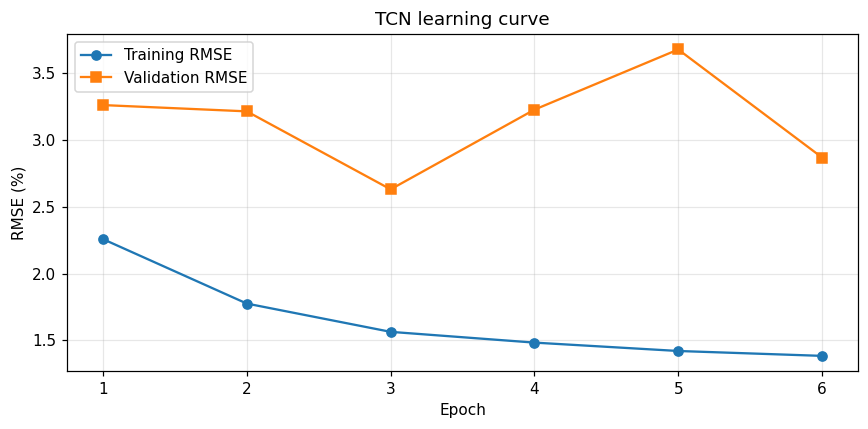

In [9]:
@torch.no_grad()
def predict(X, ends):
    model.eval()
    out = []
    for xb, _ in batches(X, np.zeros(len(ends), np.float32), ends):
        out.append(model(xb.to(DEVICE)).cpu().numpy())
    return np.concatenate(out)


opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
hist = {"train_rmse": [], "val_rmse": []}
best, best_state, wait = np.inf, None, 0
val_base = 100 * np.sqrt(np.mean((X_val[e_val, BASE_CH] - y_val) ** 2))
print(f"Validation RMSE of the physics estimate alone (before TCN correction): {val_base:.3f}%")

t_train0 = time.perf_counter()
for ep in range(1, MAX_EPOCHS + 1):
    model.train()
    se, n = 0.0, 0
    for xb, yb in batches(X_fit, y_fit, e_fit, shuffle=True, stride=TRAIN_STRIDE):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        out = model(xb)
        loss = F.huber_loss(out, yb, delta=0.02)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        se += ((out.detach() - yb) ** 2).sum().item()
        n += len(yb)
    tr = 100 * np.sqrt(se / n)
    va = 100 * np.sqrt(np.mean((predict(X_val, e_val) - y_val) ** 2))
    sched.step(va)
    hist["train_rmse"].append(tr)
    hist["val_rmse"].append(va)
    print(f"Epoch {ep:2d} | train RMSE {tr:6.3f}% | val RMSE {va:6.3f}% | lr {opt.param_groups[0]['lr']:.1e}")
    if va < best - 1e-4:
        best, wait = va, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping.")
            break
train_time_tcn = time.perf_counter() - t_train0
model.load_state_dict(best_state)
print(f"\nTCN training time: {train_time_tcn:.2f} s | best validation RMSE: {best:.4f}%")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(hist["train_rmse"]) + 1), hist["train_rmse"], "o-", label="Training RMSE")
plt.plot(range(1, len(hist["val_rmse"]) + 1), hist["val_rmse"], "s-", label="Validation RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE (%)")
plt.title("TCN learning curve")
plt.legend()
plt.tight_layout()
show("02_learning_curve")

## 5. Testing on trips #61–#70

In [10]:
def causal_smooth(pred, ids, w):
    """Causal moving average within each trip (uses only past and present estimates)."""
    if w <= 1:
        return pred
    out, s = [], 0
    for t in ids:
        n = len(trip_y[t])
        p = pd.Series(pred[s:s + n]).rolling(w, min_periods=1).mean().values
        out.append(p)
        s += n
    return np.concatenate(out)


t_inf0 = time.perf_counter()
pred_raw = predict(X_test, e_test)
pred_tcn = causal_smooth(pred_raw, test_ids, SMOOTH_WIN)
test_time_tcn = time.perf_counter() - t_inf0

actual = y_test * 100
pred_tcn_pct = pred_tcn * 100
pred_raw_pct = pred_raw * 100


def metrics(y, p):
    e = p - y
    return {"RMSE (%)": np.sqrt(np.mean(e ** 2)), "MAE (%)": np.mean(np.abs(e)),
            "MAX (%)": np.max(np.abs(e)), "STD. DEV. (%)": np.std(e)}


m_raw = metrics(actual, pred_raw_pct)
m_tcn = metrics(actual, pred_tcn_pct)
m_p2 = metrics(actual, p2_te)
print("Physics fusion only     :", {k: round(v, 4) for k, v in m_p2.items()})
print("TCN (raw output)        :", {k: round(v, 4) for k, v in m_raw.items()})
print(f"TCN (+{SMOOTH_WIN}s causal filter):", {k: round(v, 4) for k, v in m_tcn.items()})

Physics fusion only     : {'RMSE (%)': np.float64(3.4867), 'MAE (%)': np.float64(2.3973), 'MAX (%)': np.float64(11.2787), 'STD. DEV. (%)': np.float64(3.2555)}
TCN (raw output)        : {'RMSE (%)': np.float32(3.5701), 'MAE (%)': np.float32(2.6825), 'MAX (%)': np.float32(11.9477), 'STD. DEV. (%)': np.float32(3.5653)}
TCN (+60s causal filter): {'RMSE (%)': np.float64(3.5815), 'MAE (%)': np.float64(2.6937), 'MAX (%)': np.float64(11.9606), 'STD. DEV. (%)': np.float64(3.5748)}


In [11]:
if RUN_RF_BASELINE:
    Xtr_rf = np.vstack([trip_X[t] for t in all_train_ids])
    ytr_rf = np.concatenate([trip_y[t] for t in all_train_ids]) * 100
    Xte_rf = np.vstack([trip_X[t] for t in test_ids])
    rf = RandomForestRegressor(n_estimators=25, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
    t0 = time.perf_counter()
    rf.fit(Xtr_rf, ytr_rf)
    train_time_rf = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_rf = rf.predict(Xte_rf)
    test_time_rf = time.perf_counter() - t0
    m_rf = metrics(actual, pred_rf)
    print("RF (25 trees):", {k: round(v, 4) for k, v in m_rf.items()})

RF (25 trees): {'RMSE (%)': np.float64(4.9021), 'MAE (%)': np.float64(3.3739), 'MAX (%)': np.float64(20.88), 'STD. DEV. (%)': np.float64(4.832)}


In [12]:
train_time_tcn += phys_time          # physics features are part of the proposed pipeline
rows = {"Physics-informed TCN (proposed)": {**m_tcn, "Training time (s)": train_time_tcn,
                                            "Testing time (s)": test_time_tcn,
                                            "Total computation time (s)": train_time_tcn + test_time_tcn},
        "Physics fusion only (no TCN)": {**m_p2, "Training time (s)": phys_time, "Testing time (s)": np.nan,
                                         "Total computation time (s)": phys_time}}
if RUN_RF_BASELINE:
    rows["RF, 25 trees (re-implemented)"] = {**m_rf, "Training time (s)": train_time_rf,
                                             "Testing time (s)": test_time_rf,
                                             "Total computation time (s)": train_time_rf + test_time_rf}
rows["RF, 25 trees (paper, best)"] = {"RMSE (%)": 5.9028, "MAE (%)": 4.4321, "MAX (%)": 24.2175,
                                      "STD. DEV. (%)": 5.8999, "Training time (s)": np.nan,
                                      "Testing time (s)": np.nan, "Total computation time (s)": 165.28}
results = pd.DataFrame(rows).T
pd.set_option("display.float_format", "{:.4f}".format)
print("\nPERFORMANCE ON TEST DATA (testing file, {:,} instances)\n".format(len(actual)))
print(results.to_string())


PERFORMANCE ON TEST DATA (testing file, 118,974 instances)



                                 RMSE (%)  MAE (%)  MAX (%)  STD. DEV. (%)  Training time (s)  Testing time (s)  Total computation time (s)
Physics-informed TCN (proposed)    3.5815   2.6937  11.9606         3.5748           616.3272           57.5236                    673.8508
Physics fusion only (no TCN)       3.4867   2.3973  11.2787         3.2555            15.1868               NaN                     15.1868
RF, 25 trees (re-implemented)      4.9021   3.3739  20.8800         4.8320            78.2233            0.5092                     78.7325
RF, 25 trees (paper, best)         5.9028   4.4321  24.2175         5.8999                NaN               NaN                    165.2800


## 6. Simulation graphs

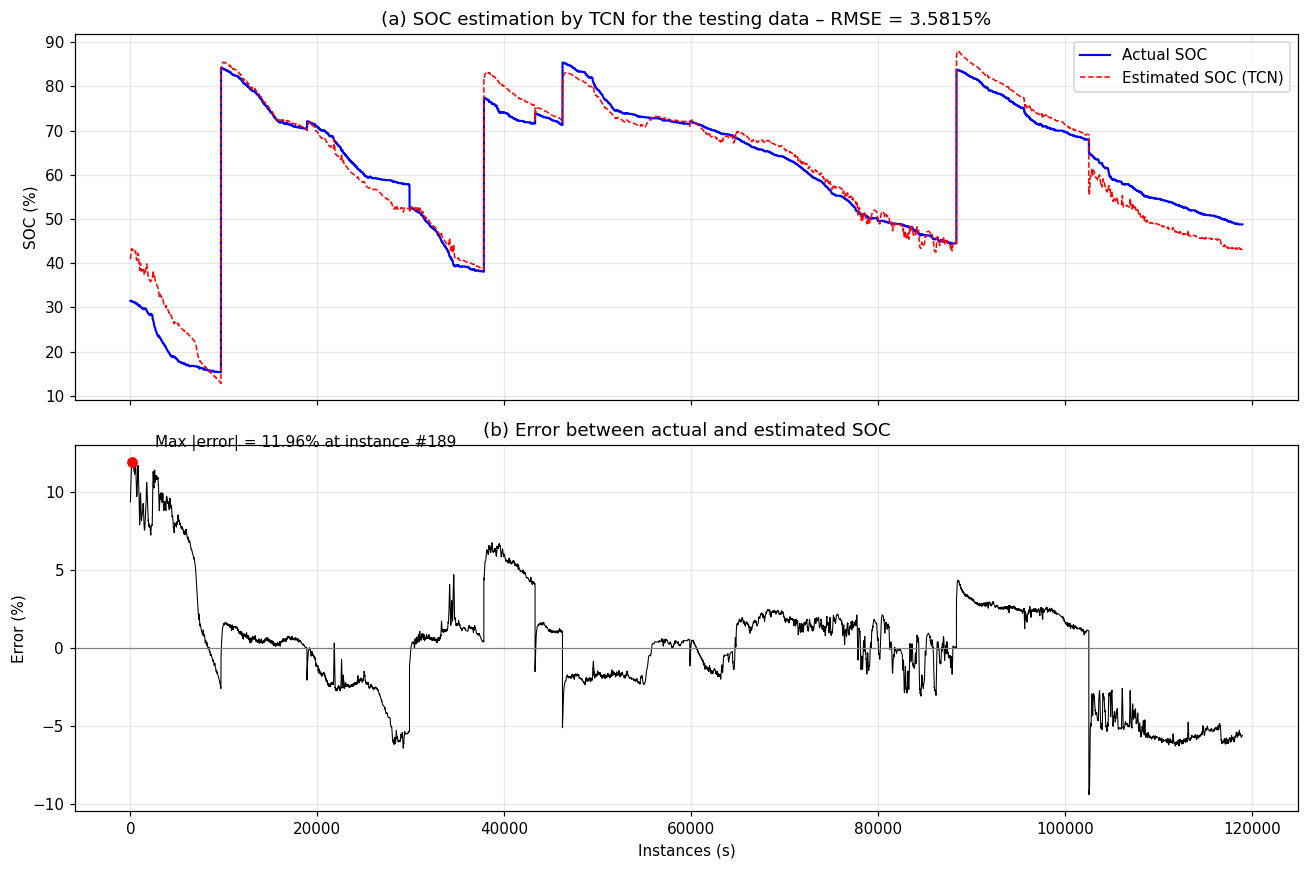

In [13]:
inst = np.arange(1, len(actual) + 1)
err_tcn = pred_tcn_pct - actual
i_max = int(np.argmax(np.abs(err_tcn)))

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].plot(inst, actual, "b", lw=1.4, label="Actual SOC")
ax[0].plot(inst, pred_tcn_pct, "r--", lw=1.0, label="Estimated SOC (TCN)")
ax[0].set_ylabel("SOC (%)")
ax[0].set_title(f"(a) SOC estimation by TCN for the testing data – RMSE = {m_tcn['RMSE (%)']:.4f}%")
ax[0].legend()
ax[1].plot(inst, err_tcn, "k", lw=0.7)
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].plot(inst[i_max], err_tcn[i_max], "ro")
ax[1].annotate(f"Max |error| = {abs(err_tcn[i_max]):.2f}% at instance #{inst[i_max]:,}",
               (inst[i_max], err_tcn[i_max]), textcoords="offset points", xytext=(15, 10))
ax[1].set_xlabel("Instances (s)")
ax[1].set_ylabel("Error (%)")
ax[1].set_title("(b) Error between actual and estimated SOC")
plt.tight_layout()
show("03_soc_tracking_and_error_TCN")

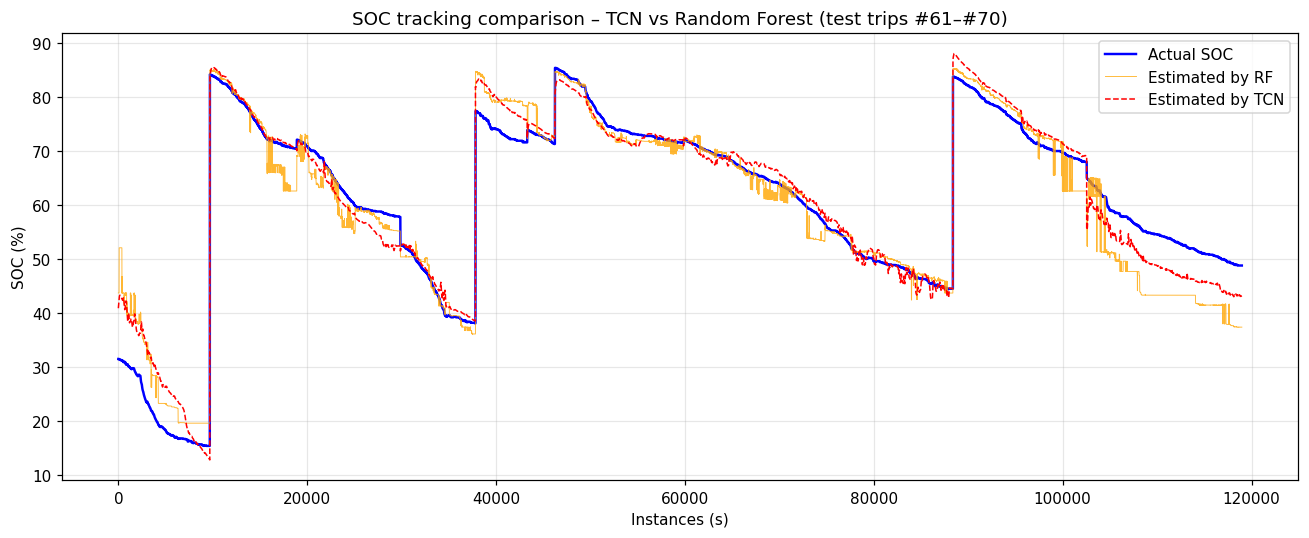

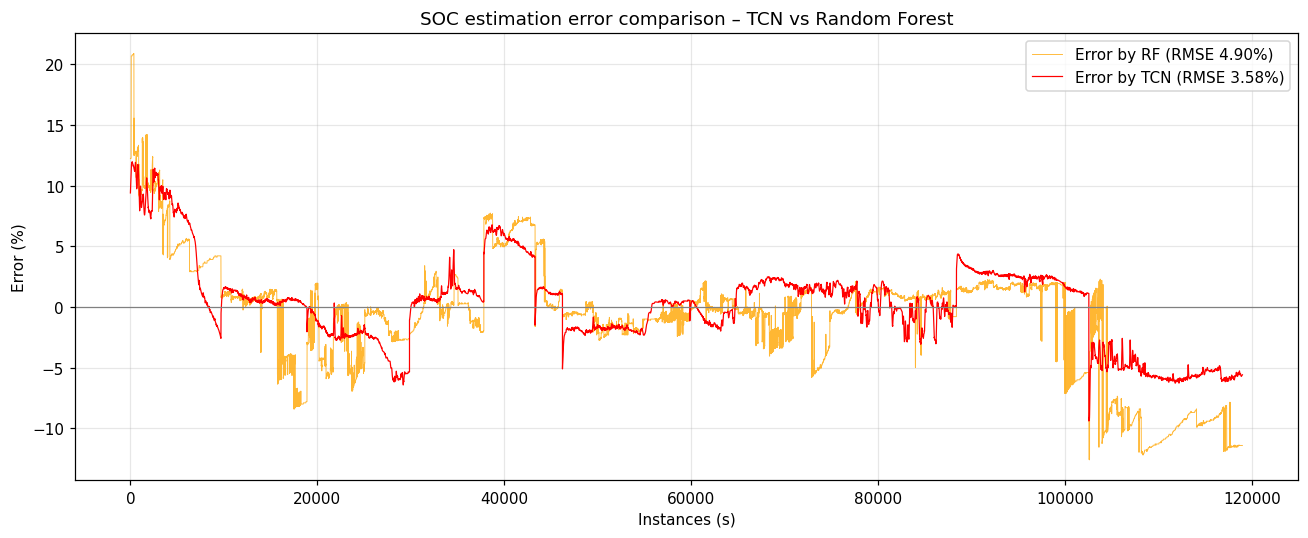

In [14]:
if RUN_RF_BASELINE:
    err_rf = pred_rf - actual
    plt.figure(figsize=(12, 5))
    plt.plot(inst, actual, "b", lw=1.6, label="Actual SOC")
    plt.plot(inst, pred_rf, color="orange", lw=0.6, alpha=0.8, label="Estimated by RF")
    plt.plot(inst, pred_tcn_pct, "r--", lw=1.0, label="Estimated by TCN")
    plt.xlabel("Instances (s)")
    plt.ylabel("SOC (%)")
    plt.title("SOC tracking comparison – TCN vs Random Forest (test trips #61–#70)")
    plt.legend()
    plt.tight_layout()
    show("04_soc_tracking_TCN_vs_RF")

    plt.figure(figsize=(12, 5))
    plt.plot(inst, err_rf, color="orange", lw=0.6, alpha=0.8, label=f"Error by RF (RMSE {m_rf['RMSE (%)']:.2f}%)")
    plt.plot(inst, err_tcn, "r", lw=0.8, label=f"Error by TCN (RMSE {m_tcn['RMSE (%)']:.2f}%)")
    plt.axhline(0, color="gray", lw=0.8)
    plt.xlabel("Instances (s)")
    plt.ylabel("Error (%)")
    plt.title("SOC estimation error comparison – TCN vs Random Forest")
    plt.legend()
    plt.tight_layout()
    show("05_soc_error_TCN_vs_RF")

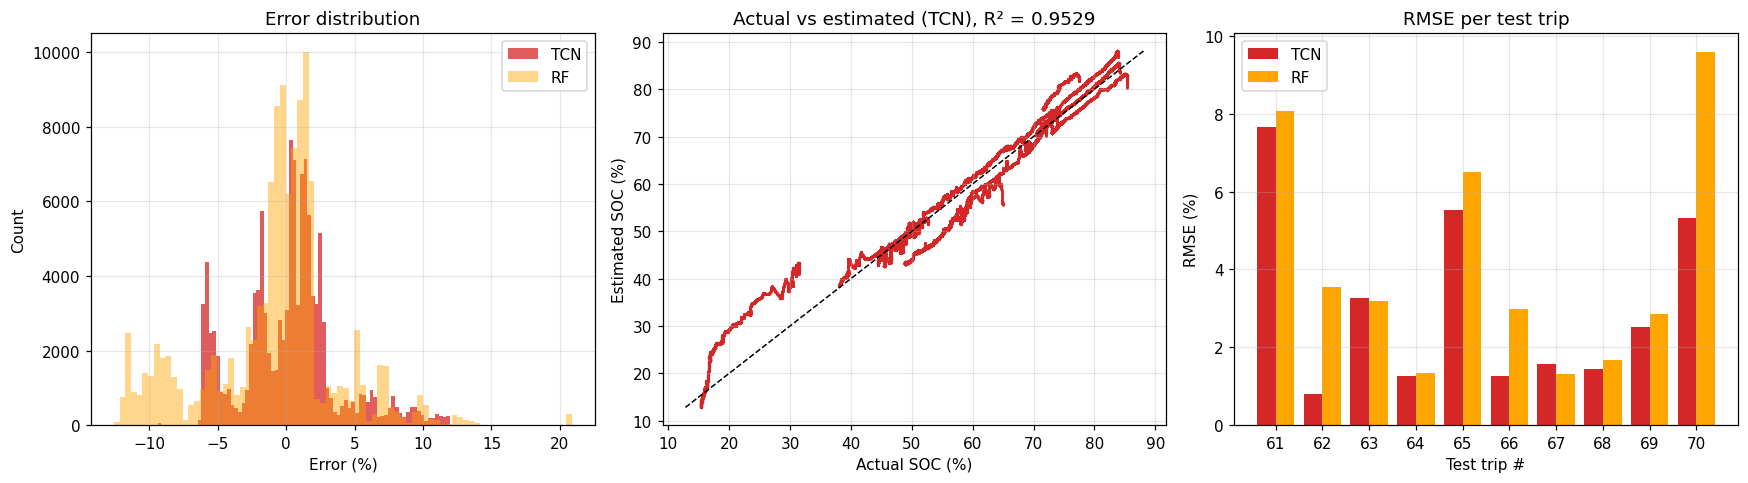

 Trip #  Set  TCN RMSE (%)  RF RMSE (%)
     61 test        7.6571       8.0690
     62 test        0.7974       3.5559
     63 test        3.2767       3.1907
     64 test        1.2709       1.3399
     65 test        5.5292       6.5008
     66 test        1.2523       2.9955
     67 test        1.5825       1.3034
     68 test        1.4531       1.6743
     69 test        2.5155       2.8534
     70 test        5.3239       9.5860


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].hist(err_tcn, bins=80, color="tab:red", alpha=0.75, label="TCN")
if RUN_RF_BASELINE:
    ax[0].hist(err_rf, bins=80, color="orange", alpha=0.45, label="RF")
ax[0].set_xlabel("Error (%)")
ax[0].set_ylabel("Count")
ax[0].set_title("Error distribution")
ax[0].legend()

ax[1].scatter(actual, pred_tcn_pct, s=1, alpha=0.25, color="tab:red")
lim = [min(actual.min(), pred_tcn_pct.min()), max(actual.max(), pred_tcn_pct.max())]
ax[1].plot(lim, lim, "k--", lw=1)
r2 = 1 - np.sum(err_tcn ** 2) / np.sum((actual - actual.mean()) ** 2)
ax[1].set_xlabel("Actual SOC (%)")
ax[1].set_ylabel("Estimated SOC (%)")
ax[1].set_title(f"Actual vs estimated (TCN), R² = {r2:.4f}")

per_trip, s = [], 0
for t in test_ids:
    n = len(trip_y[t])
    r_t = np.sqrt(np.mean(err_tcn[s:s + n] ** 2))
    r_r = np.sqrt(np.mean(err_rf[s:s + n] ** 2)) if RUN_RF_BASELINE else np.nan
    per_trip.append((t, "test", r_t, r_r))
    s += n
per_trip = pd.DataFrame(per_trip, columns=["Trip #", "Set", "TCN RMSE (%)", "RF RMSE (%)"])
xb = np.arange(len(per_trip))
ax[2].bar(xb - 0.2, per_trip["TCN RMSE (%)"], 0.4, color="tab:red", label="TCN")
if RUN_RF_BASELINE:
    ax[2].bar(xb + 0.2, per_trip["RF RMSE (%)"], 0.4, color="orange", label="RF")
ax[2].set_xticks(xb)
ax[2].set_xticklabels(per_trip["Trip #"])
ax[2].set_xlabel("Test trip #")
ax[2].set_ylabel("RMSE (%)")
ax[2].set_title("RMSE per test trip")
ax[2].legend()
plt.tight_layout()
show("06_error_hist_scatter_pertrip")
print(per_trip.to_string(index=False))

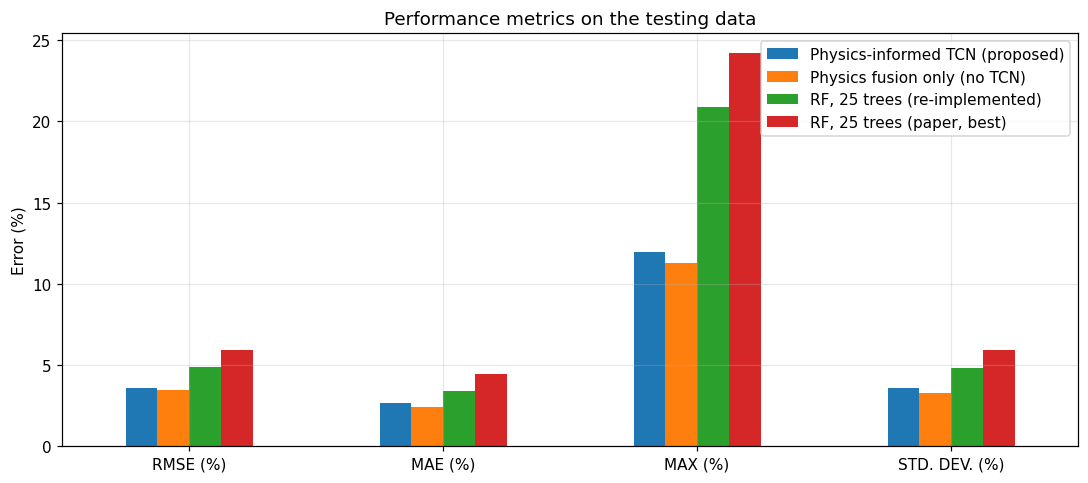

In [16]:
plot_tab = results[["RMSE (%)", "MAE (%)", "MAX (%)", "STD. DEV. (%)"]]
plot_tab.T.plot(kind="bar", figsize=(10, 4.5), rot=0)
plt.ylabel("Error (%)")
plt.title("Performance metrics on the testing data")
plt.tight_layout()
show("07_metrics_bar")

## 7. Summary

In [17]:
print("=" * 64)
print(" FINAL RESULT – TCN SOC ESTIMATION (BMW i3, testing file)")
print("=" * 64)
for k, v in m_tcn.items():
    print(f" {k:<22}: {v:.4f}")
print(f" {'Training time (s)':<22}: {train_time_tcn:.2f}")
print(f" {'Testing time (s)':<22}: {test_time_tcn:.2f}")
print(f" {'Total computation (s)':<22}: {train_time_tcn + test_time_tcn:.2f}")
print(f" {'Device':<22}: {DEVICE}")
print("=" * 64)

 FINAL RESULT – TCN SOC ESTIMATION (BMW i3, testing file)
 RMSE (%)              : 3.5815
 MAE (%)               : 2.6937
 MAX (%)               : 11.9606
 STD. DEV. (%)         : 3.5748
 Training time (s)     : 616.33
 Testing time (s)      : 57.52
 Total computation (s) : 673.85
 Device                : cpu


In [18]:
results.to_csv(os.path.join(OUT_DIR, "results_table.csv"))
per_trip.to_csv(os.path.join(OUT_DIR, "per_trip_rmse.csv"), index=False)
pred_df = pd.DataFrame({"instance": inst, "trip": test_df.trip.values, "actual_SOC": actual,
                        "TCN_SOC": pred_tcn_pct, "TCN_error": err_tcn})
if RUN_RF_BASELINE:
    pred_df["RF_SOC"], pred_df["RF_error"] = pred_rf, err_rf
pred_df.to_csv(os.path.join(OUT_DIR, "predictions_test.csv"), index=False)
torch.save(model.state_dict(), os.path.join(OUT_DIR, "tcn_best.pt"))
print("Saved tables, predictions, figures and model weights to", os.path.abspath(OUT_DIR))

Saved tables, predictions, figures and model weights to C:\Users\Rhythm Garg\OneDrive\Desktop\SOC_Assessment10\outputs
